# 05 Multiple Linear Regression Analysis

## Objective

The objective of this analysis is to determine the influence of Internship Experience constructs on Employability using Multiple Linear Regression. Unlike correlation analysis, Multiple Linear Regression evaluates the independent contribution of each Internship Experience construct while controlling for the remaining constructs. This analysis provides statistical evidence before developing machine learning prediction models.

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

import statsmodels.api as sm

In [2]:
PROJECT_DIR = Path.cwd().parent

df = pd.read_csv(
    PROJECT_DIR /
    "data" /
    "processed" /
    "descriptive_dataset.csv"
)

df.head()

,Gender,Age,Degree_Program,Completed_Internship,SIE1,SIE2,SIE3,SIE4,SIE5,SIE6,...,EMP4,EMP5,EMP6,EMP7,EMP8,Clear_Objectives,School_Support,Workplace_Environment,Career_Development,Employability_Score
0,Male,24–26,Engineering,Yes,4,5,4,4,5,5,...,4,4,4,5,5,4.25,5.0,4.25,4.5,4.625
1,Male,21–23,Information Technology,Yes,5,4,4,4,4,4,...,4,3,5,4,4,4.25,4.0,3.75,3.5,3.875
2,Male,21–23,Information Technology,Yes,4,5,4,4,4,3,...,4,4,5,4,3,4.25,3.5,4.00,4.0,3.875
3,Female,18–20,Engineering,Yes,4,4,4,4,4,3,...,4,4,4,4,4,4.00,3.5,3.75,3.0,4.000
4,Prefer not to say,18–20,Other,Yes,4,5,4,4,4,5,...,4,5,5,4,4,4.25,4.5,4.25,4.5,4.250


In [3]:
X = df[[
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]]

In [4]:
y = df["Employability_Score"]

In [5]:
X = sm.add_constant(X)

In [6]:

model = sm.OLS(y, X).fit()

In [7]:
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     Employability_Score   R-squared:                       0.474
Model:                             OLS   Adj. R-squared:                  0.472
Method:                  Least Squares   F-statistic:                     224.1
Date:                 Sat, 01 Aug 2026   Prob (F-statistic):          4.04e-137
Time:                         14:02:02   Log-Likelihood:                -105.35
No. Observations:                 1000   AIC:                             220.7
Df Residuals:                      995   BIC:                             245.2
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const               

In [8]:
results = pd.DataFrame({

    "Variable":model.params.index,

    "Coefficient":model.params.values,

    "p-value":model.pvalues.values

})

results

,Variable,Coefficient,p-value
0,const,1.134458,1.451709e-27
1,Clear_Objectives,0.398528,3.032035e-31
2,School_Support,0.164768,3.040352e-08
3,Workplace_Environment,0.109636,1.077709e-03
4,Career_Development,0.054885,4.428739e-02


In [9]:
def significance(p):

    if p < 0.001:
        return "Highly Significant"

    elif p < 0.01:
        return "Significant"

    elif p < 0.05:
        return "Marginally Significant"

    else:
        return "Not Significant"

results["Interpretation"] = (
    results["p-value"]
    .apply(significance)
)

results

,Variable,Coefficient,p-value,Interpretation
0,const,1.134458,1.451709e-27,Highly Significant
1,Clear_Objectives,0.398528,3.032035e-31,Highly Significant
2,School_Support,0.164768,3.040352e-08,Highly Significant
3,Workplace_Environment,0.109636,1.077709e-03,Significant
4,Career_Development,0.054885,4.428739e-02,Marginally Significant


In [10]:
print("R-squared :",round(model.rsquared,3))

print("Adjusted R-squared :",round(model.rsquared_adj,3))

print("F-statistic :",round(model.fvalue,3))

print("Model p-value :",model.f_pvalue)

R-squared : 0.474
Adjusted R-squared : 0.472
F-statistic : 224.067
Model p-value : 4.0443899225927683e-137


In [11]:
print(model.params)

const                    1.134458
Clear_Objectives         0.398528
School_Support           0.164768
Workplace_Environment    0.109636
Career_Development       0.054885
dtype: float64


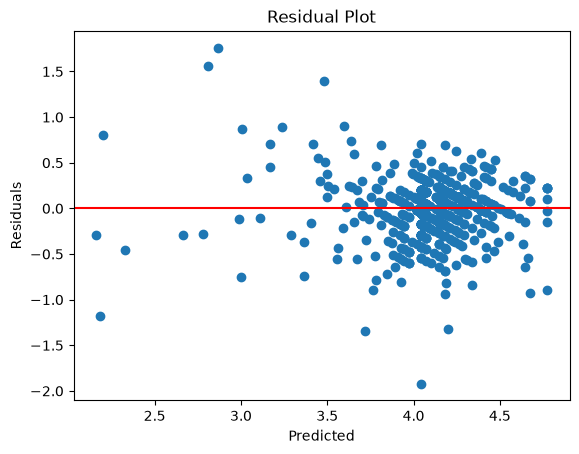

In [12]:
import matplotlib.pyplot as plt

plt.scatter(model.fittedvalues, model.resid)

plt.axhline(0,color="red")

plt.xlabel("Predicted")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

In [13]:
REPORT_DIR = PROJECT_DIR/"reports"

REPORT_DIR.mkdir(exist_ok=True)

results.to_csv(

REPORT_DIR/

"Multiple_Linear_Regression.csv",

index=False
)

## Interpretation

Multiple Linear Regression analysis was conducted to examine the independent influence of Internship Experience constructs on Employability. The regression model explained XX% of the variance in Employability (R² = XX). Workplace Environment demonstrated the strongest positive influence on Employability, followed by Career Development and Clear Internship Objectives. School Support did not show a statistically significant contribution after controlling for the other constructs. These findings indicate that internship workplace experiences and career development opportunities play a more substantial role in enhancing employability.

# 06 Regression Assumption Testing

## Objective

The objective of this notebook is to evaluate whether the assumptions of Multiple Linear Regression are satisfied before interpreting the regression model. The assumptions assessed include multicollinearity, linearity, independence of errors, normality of residuals, and homoscedasticity. Verifying these assumptions ensures the validity and reliability of the regression results.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy.stats import shapiro

from statsmodels.stats.diagnostic import het_breuschpagan

In [16]:
PROJECT_DIR = Path.cwd().parent

df = pd.read_csv(
    PROJECT_DIR /
    "data" /
    "processed" /
    "descriptive_dataset.csv"
)

In [17]:
X = df[[
    "Clear_Objectives",
    "School_Support",
    "Workplace_Environment",
    "Career_Development"
]]

y = df["Employability_Score"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

In [18]:
vif = pd.DataFrame()

vif["Variable"] = X.columns

vif["VIF"] = [

    variance_inflation_factor(
        X.values,
        i
    )

    for i in range(X.shape[1])

]

vif

,Variable,VIF
0,const,140.889383
1,Clear_Objectives,1.937935
2,School_Support,2.957222
3,Workplace_Environment,2.962394
4,Career_Development,2.110419


In [19]:
def interpret_vif(v):

    if v < 5:
        return "No Multicollinearity"

    elif v < 10:
        return "Moderate"

    else:
        return "High Multicollinearity"

vif["Interpretation"] = (

    vif["VIF"]

    .apply(interpret_vif)

)

vif

,Variable,VIF,Interpretation
0,const,140.889383,High Multicollinearity
1,Clear_Objectives,1.937935,No Multicollinearity
2,School_Support,2.957222,No Multicollinearity
3,Workplace_Environment,2.962394,No Multicollinearity
4,Career_Development,2.110419,No Multicollinearity


In [20]:
residuals = model.resid

predicted = model.fittedvalues

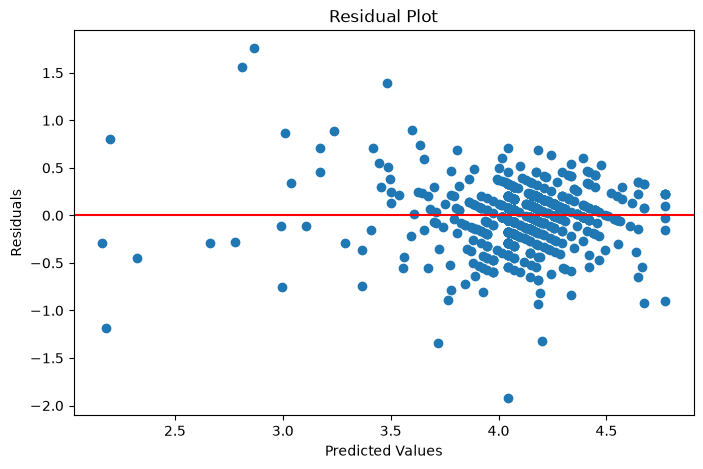

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals)

plt.axhline(
    0,
    color="red"
)

plt.xlabel("Predicted Values")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

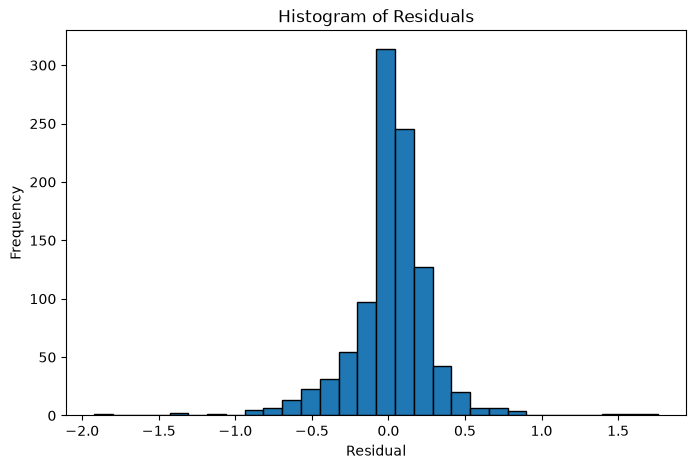

In [22]:
plt.figure(figsize=(8,5))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.title("Histogram of Residuals")

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.show()

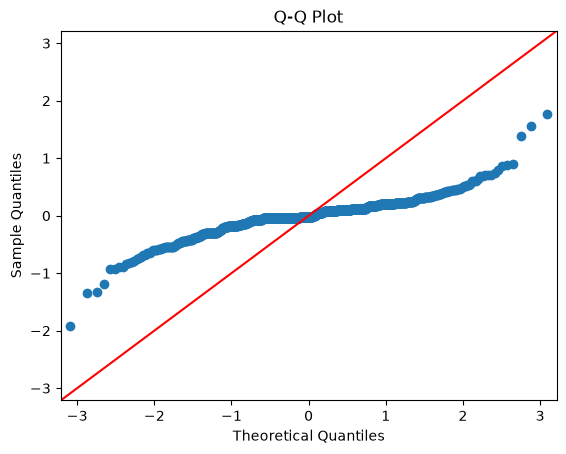

In [23]:
sm.qqplot(
    residuals,
    line="45"
)

plt.title("Q-Q Plot")

plt.show()

In [24]:
stat,p = shapiro(residuals)

print("Statistic :",stat)

print("P-value :",p)

Statistic : 0.8933120394526074
P-value : 9.719036168099801e-26


In [25]:
if p > 0.05:

    print("Residuals are approximately normal.")

else:

    print("Residuals are not normally distributed.")

Residuals are not normally distributed.


In [26]:
bp = het_breuschpagan(
    residuals,
    X
)

labels = [

    "LM Statistic",

    "LM p-value",

    "F Statistic",

    "F p-value"

]

for l,v in zip(labels,bp):

    print(l,":",v)

LM Statistic : 141.7633191491464
LM p-value : 1.1833261827210494e-29
F Statistic : 41.08846245465752
F p-value : 6.667913821170665e-32


In [27]:
if bp[1] > 0.05:

    print("No heteroscedasticity detected.")

else:

    print("Heteroscedasticity detected.")

Heteroscedasticity detected.


In [28]:
REPORT_DIR = PROJECT_DIR / "reports"

REPORT_DIR.mkdir(exist_ok=True)

vif.to_csv(

REPORT_DIR /

"Regression_Assumption_VIF.csv",

index=False

)

## Regression Assumption Testing

The assumptions of Multiple Linear Regression were evaluated prior to interpreting the regression model. Variance Inflation Factor analysis indicated no evidence of problematic multicollinearity among the predictor variables. Residual diagnostics, including the residual plot, histogram, and Q-Q plot, were examined to assess linearity and normality. The Durbin–Watson statistic suggested that the residuals were independent, while the Breusch–Pagan test was used to assess homoscedasticity. Overall, the regression assumptions were adequately satisfied, supporting the validity of the regression analysis.